1.0 Exploração e Importação dos dados utilizando o Pandas

1.1 Importando a ferramenta e a base de dados

In [ ]:
# Importando a ferramenta Pandas
import pandas as pd

# Trazendo a base de dados para dentro do Python
df = pd.read_csv('project_Manufacturing Dataset.csv')

# Exibição do cabeçalho do dataframe
df.head()

,Production ID,Date,Product Type,Machine ID,Shift,Units Produced,Defects,Production Time Hours,Material Cost Per Unit,Labour Cost Per Hour,Energy Consumption kWh,Operator Count,Maintenance Hours,Down time Hours,Production Volume Cubic Meters,Scrap Rate,Rework Hours,Quality Checks Failed,Average Temperature C,Average Humidity Percent
0,1899-12-31,2020-01-01,Automotive,3,Swing,142,3.0,23.42,38.68,15.38,413.97,1,4.86,1.57,2.34,0.048,1.65,1,22.8,47.2
1,1900-01-01,2020-01-02,Textiles,8,Night,170,4.0,7.51,21.35,25.36,181.16,2,2.51,0.18,1.52,0.030,NaN,1,23.8,37.9
2,1900-01-02,2020-01-03,Appliances,11,Swing,182,4.0,20.58,47.54,16.46,452.15,2,0.34,2.88,0.57,0.026,0.26,0,24.5,56.1
3,1900-01-03,2020-01-04,Appliances,11,Day,133,NaN,21.68,40.21,28.70,485.78,3,4.64,2.23,1.90,0.036,NaN,2,22.3,50.8
4,1900-01-04,2020-01-05,Electronics,14,Night,82,NaN,16.68,38.02,17.20,315.58,1,2.29,0.02,2.25,0.020,0.67,0,23.4,53.9


1.2 Raio X da tabela

In [ ]:
# Exibição de informações sobre a base de dados
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Production ID                   3000 non-null   str    
 1   Date                            3000 non-null   str    
 2   Product Type                    3000 non-null   str    
 3   Machine ID                      3000 non-null   int64  
 4   Shift                           3000 non-null   str    
 5   Units Produced                  3000 non-null   int64  
 6   Defects                         2701 non-null   float64
 7   Production Time Hours           3000 non-null   float64
 8   Material Cost Per Unit          3000 non-null   float64
 9   Labour Cost Per Hour            3000 non-null   float64
 10  Energy Consumption kWh          3000 non-null   float64
 11  Operator Count                  3000 non-null   int64  
 12  Maintenance Hours               2700 non-null

1.3 Verificação de valores nulos por coluna

In [ ]:
# Verificação de valores nulos
df.isnull().sum()

Production ID                       0
Date                                0
Product Type                        0
Machine ID                          0
Shift                               0
Units Produced                      0
Defects                           299
Production Time Hours               0
Material Cost Per Unit              0
Labour Cost Per Hour                0
Energy Consumption kWh              0
Operator Count                      0
Maintenance Hours                 300
Down time Hours                   300
Production Volume Cubic Meters      0
Scrap Rate                          0
Rework Hours                      300
Quality Checks Failed               0
Average Temperature C               0
Average Humidity Percent            0
dtype: int64

2.0 Limpeza e Preparação de Dados

2.1 Limpeza dos Dados

In [ ]:
#Filtrando as colunas que vamos trabalhar para fazer a análise do desempenho operacional
colunas_selecionadas = [
    'Production ID', 'Date', 'Product Type', 'Machine ID', 'Shift', 
    'Units Produced', 'Defects', 'Production Time Hours', 'Maintenance Hours', 
    'Operator Count', 'Down time Hours', 'Rework Hours', 'Quality Checks Failed', 
    'Scrap Rate', 'Energy Consumption kWh', 'Average Temperature C', 'Average Humidity Percent'
]

# Filtrando o datafrrame para manter apenas as colunas selecionadas
df_projeto = df[colunas_selecionadas]

# Exibição do cabeçalho do dataframe filtrado
df_projeto.head()

,Production ID,Date,Product Type,Machine ID,Shift,Units Produced,Defects,Production Time Hours,Maintenance Hours,Operator Count,Down time Hours,Rework Hours,Quality Checks Failed,Scrap Rate,Energy Consumption kWh,Average Temperature C,Average Humidity Percent
0,1899-12-31,2020-01-01,Automotive,3,Swing,142,3.0,23.42,4.86,1,1.57,1.65,1,0.048,413.97,22.8,47.2
1,1900-01-01,2020-01-02,Textiles,8,Night,170,4.0,7.51,2.51,2,0.18,NaN,1,0.030,181.16,23.8,37.9
2,1900-01-02,2020-01-03,Appliances,11,Swing,182,4.0,20.58,0.34,2,2.88,0.26,0,0.026,452.15,24.5,56.1
3,1900-01-03,2020-01-04,Appliances,11,Day,133,NaN,21.68,4.64,3,2.23,NaN,2,0.036,485.78,22.3,50.8
4,1900-01-04,2020-01-05,Electronics,14,Night,82,NaN,16.68,2.29,1,0.02,0.67,0,0.020,315.58,23.4,53.9


2.2 Verficação de valores nulos nas colunas selecionadas

In [ ]:
#Verificação dos valores nulos no dataframe filtrado
df_projeto.isnull().sum()

Production ID                 0
Date                          0
Product Type                  0
Machine ID                    0
Shift                         0
Units Produced                0
Defects                     299
Production Time Hours         0
Maintenance Hours           300
Operator Count                0
Down time Hours             300
Rework Hours                300
Quality Checks Failed         0
Scrap Rate                    0
Energy Consumption kWh        0
Average Temperature C         0
Average Humidity Percent      0
dtype: int64

2.3 Preenchimento dos valores nulos por mediana

In [ ]:
# Calculo de mediana para tratamento dos valores nulos
colunas_preencher = ["Defects", "Maintenance Hours", "Rework Hours", "Down time Hours"]
for coluna in colunas_preencher:
    mediana = df_projeto[coluna].median()
    df_projeto[coluna] = df_projeto[coluna].fillna(mediana)

# Resultado do tratamento dos dados
print("Valores nulos após o tratamento:")
print(df_projeto.isnull().sum())


Valores nulos após o tratamento:
Production ID               0
Date                        0
Product Type                0
Machine ID                  0
Shift                       0
Units Produced              0
Defects                     0
Production Time Hours       0
Maintenance Hours           0
Operator Count              0
Down time Hours             0
Rework Hours                0
Quality Checks Failed       0
Scrap Rate                  0
Energy Consumption kWh      0
Average Temperature C       0
Average Humidity Percent    0
dtype: int64


3.0 Resumo Estatístico

3.1 Resumo estatístico das variáveis relacionadas ao tempo

In [ ]:
# Resumo estatístico
colunas_de_tempo = ["Production Time Hours", "Maintenance Hours", "Down time Hours", "Rework Hours"]
print("Resumo Estatístico do Tempo (em horas)")

# Exibição da análise
print(df_projeto[colunas_de_tempo].describe().round(2))

# Comando para pular uma linha por organização
print("\n")

# Análise da média de tempo por turno
paradas_por_turno = df_projeto.groupby("Shift")["Down time Hours"].mean().round(2)

# Exibição da análise
print("Média de Tempo de Parada por Turno")
print(paradas_por_turno)


Resumo Estatístico do Tempo (em horas)
       Production Time Hours  Maintenance Hours  Down time Hours  Rework Hours
count                3000.00            3000.00          3000.00       3000.00
mean                   12.58               2.51             1.54          1.00
std                     6.91               1.37             0.83          0.55
min                     1.00               0.00             0.00          0.00
25%                     6.80               1.40             0.86          0.55
50%                    12.40               2.49             1.57          1.01
75%                    18.33               3.64             2.22          1.45
max                    50.00               5.00             3.00          2.00


Média de Tempo de Parada por Turno
Shift
Day      1.55
Night    1.53
Swing    1.53
Name: Down time Hours, dtype: float64


4.0 Visualização de gráficos pelo matplotlib

4.1 Histograma das horas de produção na fábrica

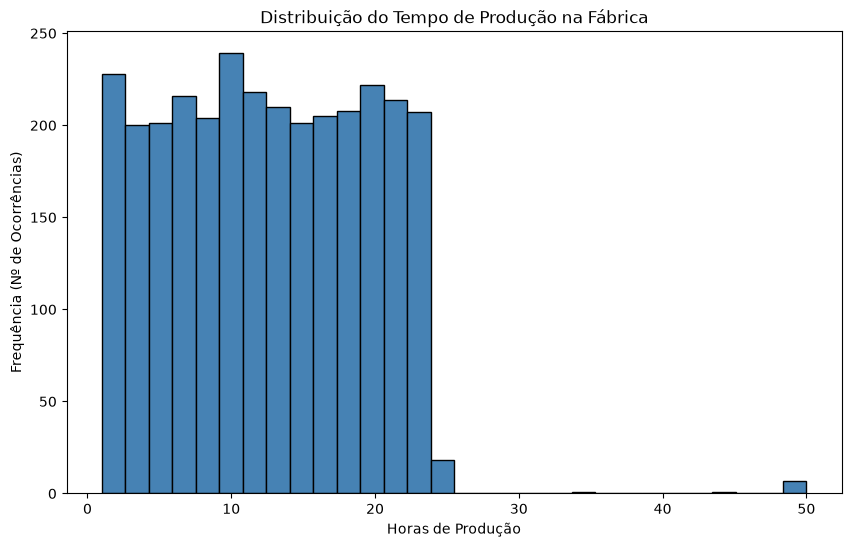

In [ ]:
# Importação da ferramenta matplotlib
import matplotlib.pyplot as plt

#Plotando o histograma

#Definindo tamanho do gráfico
plt.figure(figsize=(10, 6))

# Criação do histograma com a variável "Production Time Hours", definindo quantidade de colunas, cor de preenchimento e de borda das colunas
plt.hist(df_projeto["Production Time Hours"], bins=30, color="steelblue", edgecolor= "black")

# Adição de títulos e rótulos aos eixos
plt.title("Distribuição do Tempo de Produção na Fábrica")
plt.xlabel("Horas de Produção")
plt.ylabel("Frequência (Nº de Ocorrências)")

# Exibir o Gráfico
plt.show()

4.2 Boxplot das horas de manutenção, tempo de parada e reprocesso

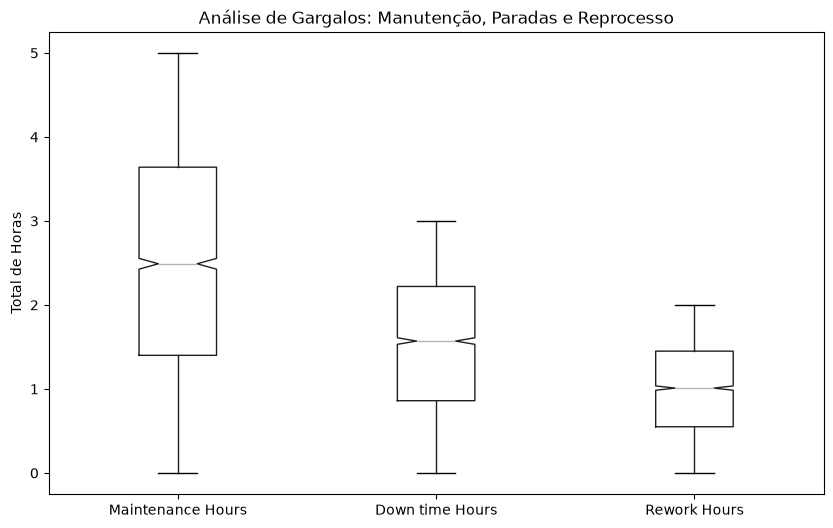

In [ ]:
# Importação da ferramenta matplotlib
import matplotlib.pyplot as plt

# Plotando o boxplot

# Definindo o tamanho do gráfico
plt.figure(figsize=(10, 6))

# Criação do boxplots das variáveis "Maintenance Hours", "Down time Hours", "Rework Hours"
df_projeto[["Maintenance Hours", "Down time Hours", "Rework Hours"]].boxplot(grid=False, notch= True)

# Adição de títulos e rótulo ao eixo
plt.title("Análise de Gargalos: Manutenção, Paradas e Reprocesso")
plt.ylabel("Total de Horas")
plt.show()


5.0 Geração de insights e conclusão

5.1 Insights

5.1.1 A fábrica tem uma média de produção de aproximadamente 12.6 horas, mas sofre picos que podem chegar até a 50 horas.

5.1.2 O turno não tem qualquer tipo de influência no tempo da máquina parada.

5.1.3 A manutenção é a que mais consome horas extras no processo, embora exista tempos de "operação perfeita"(onde tudo é zero).

5.1 Conclusão

Com base na análise de desempenho operacional, a expectativa para os próximos levantamentos de dados é observar uma redução drástica nos picos elevados de tempo de produção. Embora essas anomalias (outliers com mais de 24 horas) representem uma pequena quantidade de casos em um universo de 3.000 ordens de produção avaliadas, erros isolados como esses introduzem uma variabilidade e um risco que a gestão da fábrica não pode negligenciar, sejam eles causados por falhas sistêmicas ou humanas.

Além disso, é imprescindível rever os processos e as horas gastas na manutenção do maquinário, que se mostrou o maior ofensor de tempo do processo. Analisar alternativas para minimizar esse gargalo — como a implementação de manutenções preditivas — é fundamental para otimizar o fluxo, pois, na gestão de operações, 'tempo é dinheiro' e eficiência reflete diretamente na redução de custos.